# Experiment 8: Sugeno Fuzzy Inference System

**Aim:** To implement a simple Sugeno Fuzzy Inference System using Python.

## Theory
In a **Sugeno (TSK)** system, rule consequents are crisp functions of the inputs:

* Zero-order: `THEN z = c`
* First-order: `THEN z = p·x + q·y + r`

Final output is the **weighted average**: z = Σ(wᵢ·zᵢ) / Σwᵢ, where wᵢ is the firing strength of rule i.
No separate defuzzification step is needed.

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
%matplotlib inline

### Step 2: Input membership functions (x: 0-10, y: 0-10)

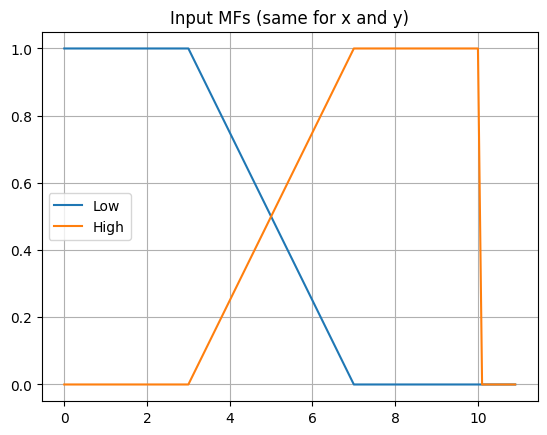

In [2]:
x = np.arange(0, 11, 0.1)
x_low  = lambda v: float(fuzz.interp_membership(x, fuzz.trapmf(x, [0, 0, 3, 7]), v))
x_high = lambda v: float(fuzz.interp_membership(x, fuzz.trapmf(x, [3, 7, 10, 10]), v))

# plot
plt.plot(x, fuzz.trapmf(x, [0, 0, 3, 7]), label='Low')
plt.plot(x, fuzz.trapmf(x, [3, 7, 10, 10]), label='High')
plt.title('Input MFs (same for x and y)'); plt.legend(); plt.grid(True); plt.show()

### Step 3: Rule base (first-order Sugeno)
| Rule | IF x is | AND y is | THEN z = |
|---|---|---|---|
| R1 | Low  | Low  | 1·x + 1·y + 0 |
| R2 | Low  | High | 2·x + 0.5·y + 1 |
| R3 | High | Low  | 0.5·x + 2·y + 1 |
| R4 | High | High | 3·x + 3·y + 2 |

In [3]:
def sugeno(xv, yv, verbose=False):
    # fuzzification
    xl, xh = x_low(xv),  x_high(xv)
    yl, yh = x_low(yv),  x_high(yv)
    # firing strengths (AND = product)
    w = np.array([xl*yl, xl*yh, xh*yl, xh*yh])
    # crisp rule outputs
    z = np.array([
        1*xv + 1*yv + 0,
        2*xv + 0.5*yv + 1,
        0.5*xv + 2*yv + 1,
        3*xv + 3*yv + 2,
    ])
    out = np.sum(w*z) / np.sum(w)
    if verbose:
        for i in range(4): print(f"R{i+1}: w = {w[i]:.3f}, z = {z[i]:.3f}")
        print(f"Output = sum(w*z)/sum(w) = {out:.3f}")
    return out

sugeno(2, 8, verbose=True)

R1: w = 0.000, z = 10.000
R2: w = 1.000, z = 9.000
R3: w = 0.000, z = 18.000
R4: w = 0.000, z = 32.000
Output = sum(w*z)/sum(w) = 9.000


np.float64(9.0)

### Step 4: Zero-order Sugeno (constant consequents)

In [4]:
def sugeno_zero(xv, yv):
    w = np.array([x_low(xv)*x_low(yv), x_low(xv)*x_high(yv), x_high(xv)*x_low(yv), x_high(xv)*x_high(yv)])
    z = np.array([2, 5, 5, 9])
    return np.sum(w*z)/np.sum(w)

for p in [(0, 0), (2, 8), (5, 5), (10, 10)]:
    print(p, '-> first-order:', round(sugeno(*p), 3), '| zero-order:', round(sugeno_zero(*p), 3))

(0, 0) -> first-order: 0.0 | zero-order: 2.0
(2, 8) -> first-order: 9.0 | zero-order: 5.0
(5, 5) -> first-order: 17.25 | zero-order: 5.25
(10, 10) -> first-order: 62.0 | zero-order: 9.0


### Step 5: Output surface

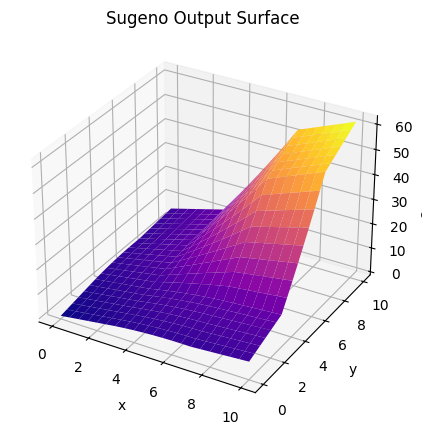

In [5]:
g = np.arange(0, 10.5, 0.5)
X, Y = np.meshgrid(g, g)
Z = np.vectorize(sugeno)(X, Y)
fig = plt.figure(figsize=(7, 5)); ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='plasma')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('Output z'); ax.set_title('Sugeno Output Surface')
plt.show()

## Conclusion
A first-order and zero-order Sugeno FIS was implemented in Python. The output is computed as the weighted average of crisp rule outputs, which is computationally efficient and gives smooth surfaces.